In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import machine_learning_models as mlm
pd.set_option('display.max_rows', 100)

In [ ]:
df = pd.read_csv(r'C:\Users\mechz\Documents\Jobs_Analysis\job_postings.csv')
X = df.drop(columns=['salary_year_avg'])
predictors = X.columns.to_list()
numerical_columns = ['job_posted_year', 'job_posted_month_sine']
numerical_indices = X.columns.get_indexer(numerical_columns)
X = X.to_numpy()
y = df['salary_year_avg'].to_numpy()

training_index, testing_index = mlm.train_test_split(X.shape[0], 10000)
X_training = X[training_index]
y_training = y[training_index]
X_testing = X[testing_index]
y_testing = y[testing_index]

for index in numerical_indices:
    mean = np.mean(X_training[:,index])
    std = np.std(X_training[:, index])
    X_training[:,index] = (X_training[:,index] - mean) / std
    X_testing[:,index] = (X_testing[:,index] - mean) / std

print(f'The mean, median, and standard deviation of the salary are {np.mean(y):.3f}, {np.median(y):.3f}, and {np.std(y):.3f} respectively.')

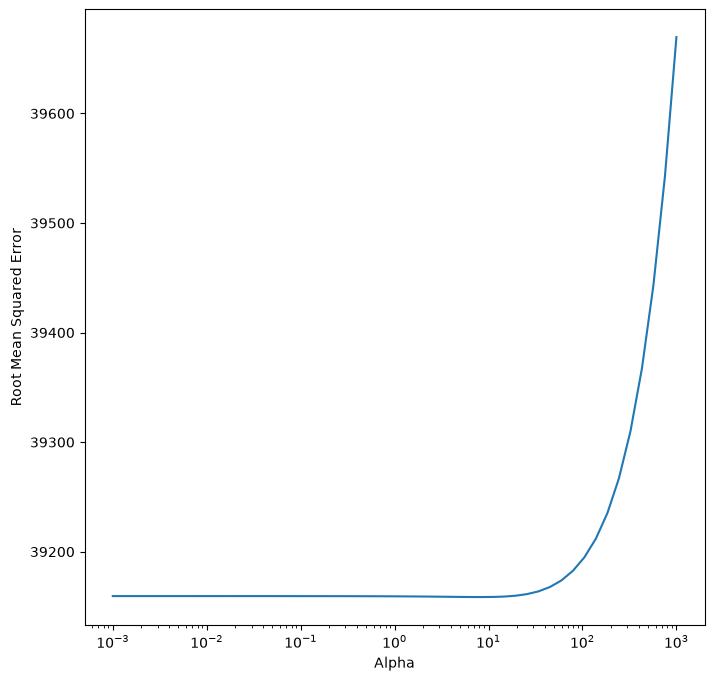

The best alpha value is 8.286 which gives a testing root mean squared error of 40718.209 and testing R squared score of 0.279.


,value
variable,
job_title_short_Senior Data Scientist,21418.821616
job_country_South Africa,15620.149068
job_country_United States,13871.336734
job_title_short_Senior Data Engineer,13369.746645
job_country_Sudan,11137.078747
job_via_LinkedIn,10826.274063
job_via_Built In,10368.328520
job_title_short_Software Engineer,8904.498382
job_title_short_Machine Learning Engineer,8645.848247


In [3]:
alphas = np.logspace(-3, 3, 50)
rmses = {}
for alpha in alphas:
    rmses_one_fold = []
    for fold in mlm.kfold_cross_validation(5, X_training.shape[0]):
        inner_model = mlm.Ridge_Regression()
        inner_model.fit(np.delete(X_training, fold, axis=0), np.delete(y_training, fold, axis=0), alpha=alpha)
        predictions = inner_model.predict(X_training[fold])
        rmse = np.sqrt(np.mean((y_training[fold] - predictions)**2))
        rmses_one_fold.append(rmse)
    average_rmse = np.mean(rmses_one_fold)
    rmses.update({alpha:average_rmse})
best_alpha = min(rmses, key=rmses.get)

fig, ax = plt.subplots(figsize=(8,8))
ax.semilogx(rmses.keys(), rmses.values())
ax.set_xlabel('Alpha')
ax.set_ylabel('Root Mean Squared Error')
plt.show()

final_model = mlm.Ridge_Regression()
final_model.fit(X_training, y_training, alpha=best_alpha)
predictions = final_model.predict(X_testing)
rmse = np.sqrt(np.mean((y_testing - predictions)**2))
r2 = 1 - (np.sum((y_testing - predictions)**2)) / (np.sum((y_testing - np.mean(y_testing))**2))

print(f'The best alpha value is {best_alpha:.3f} which gives a testing root mean squared error of {rmse:.3f} and testing R squared score of {r2:.3f}.')
full_model = mlm.Ridge_Regression()
full_model.fit(X, y, alpha=best_alpha)
parameters = predictors
parameters_dictionary = dict(zip(parameters, full_model.parameters))
parameters_df = pd.DataFrame(parameters_dictionary)
parameters_df = pd.melt(parameters_df).set_index('variable', drop=True).sort_values(by='value', ascending=False)
display(parameters_df)

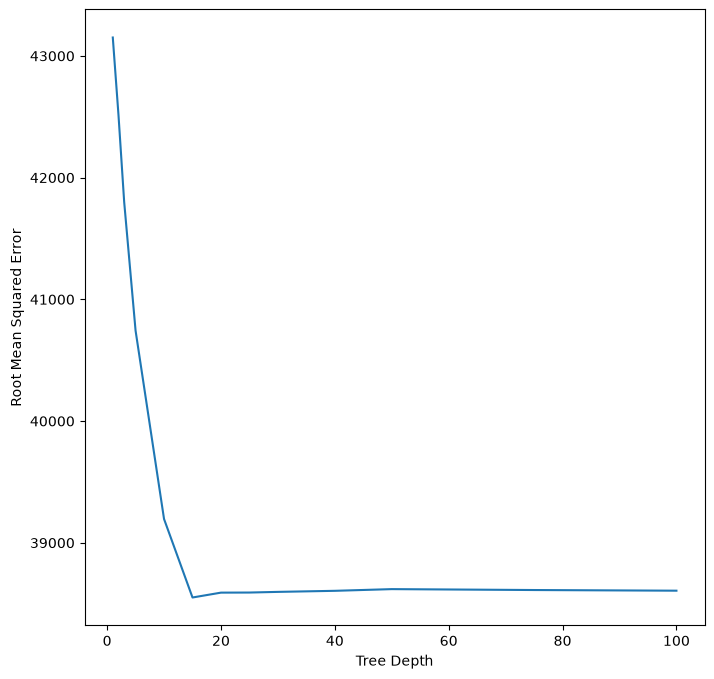

The best tree depth is 15 which gives a testing root mean squared error of 40441.309 and testing R squared score of 0.288.


,permutation_importance,sse_importance,direction
variables,,,
job_title_short_Data Analyst,27.33,36.35,-40099.502980
job_health_insurance,12.06,5.84,13007.576540
job_country_other,5.94,2.20,-3163.944673
job_via_LinkedIn,4.22,3.29,9912.805785
job_via_other,3.28,2.91,4693.981219
skills_excel,3.27,2.69,-8218.473100
job_title_short_Data Engineer,3.22,1.94,-5061.346508
job_title_short_Business Analyst,3.02,5.76,-29008.974069
job_via_Ladders,3.00,1.83,5083.614560


In [4]:
depths = [1, 2, 3, 5, 10, 15, 20, 25, 30, 40, 50, 75, 100]
rmses = []
for depth in depths:
    rmses_one_fold = []
    for fold in mlm.kfold_cross_validation(5, len(y_training)):
        inner_model = mlm.Regression_Tree(X.shape[1], max_depth=depth)
        inner_model.fit(np.delete(X_training, fold, axis=0), np.delete(y_training, fold))
        predictions = inner_model.predict(X_training[fold])
        rmse = np.sqrt(np.mean((y_training[fold] - predictions)**2))
        rmses_one_fold.append(rmse)
    rmses.append(np.mean(rmses_one_fold))
lowest_rmse = min(rmses)
best_depth = depths[rmses.index(lowest_rmse)]

fig, ax = plt.subplots(figsize=(8,8))
ax.plot(depths, rmses)
ax.set_xlabel('Tree Depth')
ax.set_ylabel('Root Mean Squared Error')
plt.show()

full_model = mlm.Regression_Tree(X.shape[1], max_depth=best_depth)
full_model.fit(X_training, y_training)
predictions = inner_model.predict(X_testing)
rmse = np.sqrt(np.mean((y_testing - predictions)**2))
r2 = 1 - (np.sum((y_testing - predictions)**2)) / (np.sum((y_testing - np.mean(y_testing))**2))
print(f'The best tree depth is {best_depth} which gives a testing root mean squared error of {rmse:.3f} and testing R squared score of {r2:.3f}.')

parameters = predictors
parameters_dictionary = {'variables':parameters, 'permutation_importance':np.round(full_model.permutation_importances(X_testing, y_testing) * 100, 2), 'sse_importance':np.round(full_model.feature_importances() * 100, 2), 'direction':full_model.direction_of_change()}
parameters_df = pd.DataFrame(parameters_dictionary).sort_values(by='permutation_importance', ascending=False).set_index('variables', drop=True)
display(parameters_df)

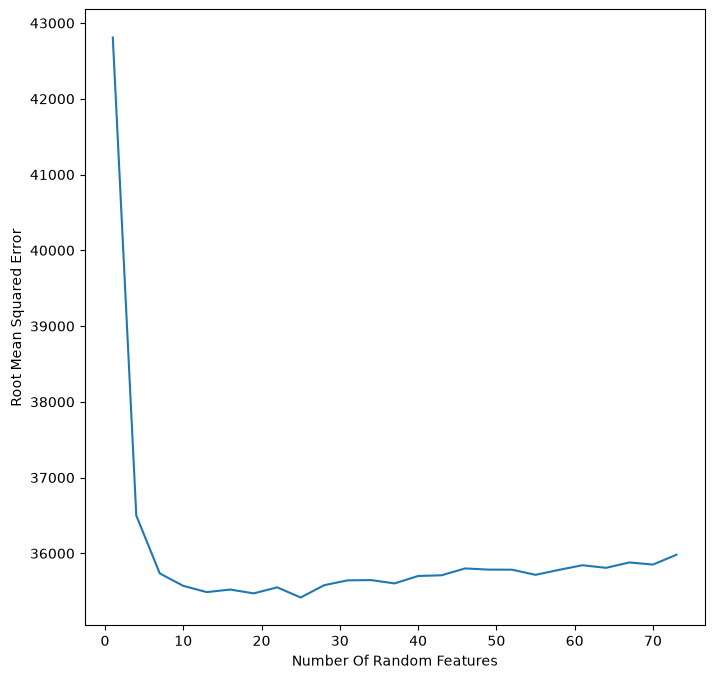

The best number of random features is 25 which gives a testing root mean squared error of 36856.499 and testing R squared score of 0.409.


,permutation_importance,sse_importance,direction
variables,,,
job_title_short_Data Analyst,11.79,15.02,-33215.809502
job_health_insurance,8.27,3.11,11065.406326
skills_python,4.91,3.52,10203.658722
skills_excel,4.54,5.62,-17994.637932
job_via_LinkedIn,3.52,2.15,8820.889010
job_country_United States,3.19,1.26,4647.206425
skills_spark,3.19,1.91,7916.305255
job_via_other,3.01,1.79,4029.827150
job_title_short_Senior Data Scientist,2.75,2.50,16904.011863


In [ ]:
random_feature_numbers = np.unique(np.linspace(1, X_training.shape[1], 3).astype(np.int32))
rmses = []
for random_feature_number in random_feature_numbers:
    rmses_one_fold = []
    for fold in mlm.kfold_cross_validation(3, len(y_training)):
        inner_model = mlm.Regression_Random_Forest(number_of_trees=5, number_of_random_features=random_feature_number)
        inner_model.fit(np.delete(X_training, fold, axis=0), np.delete(y_training, fold, axis=0))
        predictions = inner_model.predict(X_training[fold])
        rmse = np.sqrt(np.mean((y_training[fold] - predictions)**2))
        rmses_one_fold.append(rmse)
    rmses.append([np.mean(rmses_one_fold), random_feature_number])
rmses = np.array(rmses)
row_number = np.argmin(rmses[:, 0])
best_random_feature_number = int(rmses[row_number, 1])

fig, ax = plt.subplots(figsize=(8,8))
ax.plot(rmses[:, 1], rmses[:, 0])
ax.set_xlabel('Number Of Random Features')
ax.set_ylabel('Root Mean Squared Error')
plt.show()

full_model = mlm.Regression_Random_Forest(number_of_trees=50, number_of_random_features=best_random_feature_number)
full_model.fit(X_training, y_training)
predictions = full_model.predict(X_testing)
rmse = np.sqrt(np.mean((y_testing - predictions)**2))
r2 = 1 - (np.sum((y_testing - predictions)**2)) / (np.sum((y_testing - np.mean(y_testing))**2))
print(f'The best number of random features is {best_random_feature_number} which gives a testing root mean squared error of {rmse:.3f} and testing R squared score of {r2:.3f}.')

parameters = predictors
parameters_dictionary = {'variables':parameters, 'permutation_importance':np.round(full_model.permutation_importances(X_testing, y_testing) * 100, 2), 'sse_importance':np.round(full_model.feature_importances() * 100, 2), 'direction':full_model.direction_of_change()}
parameters_df = pd.DataFrame(parameters_dictionary).sort_values(by='permutation_importance', ascending=False).set_index('variables', drop=True)
display(parameters_df)

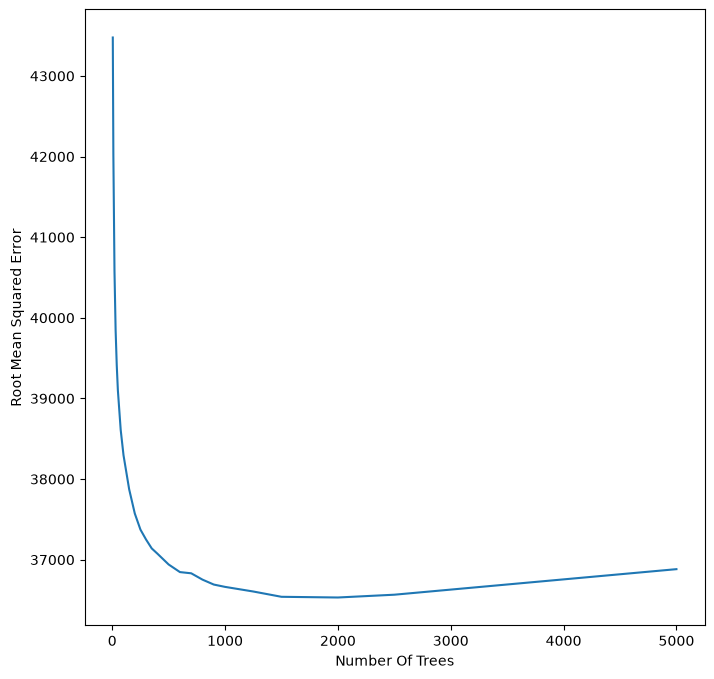

The best number of trees is 2000 which gives a testing root mean squared error of 37942.451 and testing R squared score of 0.374.


c:\Users\mechz\Documents\Jobs_Analysis\machine_learning_models.py:202: RuntimeWarning: invalid value encountered in divide
  permutation_importances = permutation_importances / np.sum(permutation_importances)


,permutation_importance,sse_importance,direction
variables,,,
job_work_from_home,NaN,1.08,0.305589
job_no_degree_mention,NaN,0.66,-6.466589
job_health_insurance,NaN,5.12,53.281588
job_posted_year,NaN,0.87,66.699565
job_posted_month_sine,NaN,1.89,-11.740387
Contractor,NaN,0.57,-49.001854
Full-time,NaN,0.60,35.259840
Internship,NaN,0.56,-190.402583
Part-time,NaN,0.50,3.830895


In [ ]:
number_of_trees = [5, 10, 20]
rmses = []
for tree_number in number_of_trees:
    rmses_one_fold = []
    for fold in mlm.kfold_cross_validation(3, len(y_training)):
        inner_model = mlm.Regression_Gradient_Boosting(number_of_trees=tree_number)
        inner_model.fit(np.delete(X_training, fold, axis=0), np.delete(y_training, fold, axis=0))
        predictions = inner_model.predict(X_training[fold])
        rmse = np.sqrt(np.mean((y_training[fold] - predictions)**2))
        rmses_one_fold.append(rmse)
    rmses.append([np.mean(rmses_one_fold), tree_number])
rmses = np.array(rmses)
row_number = np.argmin(rmses[:, 0])
best_tree_number = int(rmses[row_number, 1])

fig, ax = plt.subplots(figsize=(8,8))
ax.plot(rmses[:, 1], rmses[:, 0])
ax.set_xlabel('Number Of Trees')
ax.set_ylabel('Root Mean Squared Error')
plt.show()

full_model = mlm.Regression_Gradient_Boosting(number_of_trees=best_tree_number)
full_model.fit(X_training, y_training)
predictions = full_model.predict(X_testing, y_testing)
rmse = np.sqrt(np.mean((y_testing - predictions)**2))
r2 = 1 - (np.sum((y_testing - predictions)**2)) / (np.sum((y_testing - np.mean(y_testing))**2))
print(f'The best number of trees is {best_tree_number} which gives a testing root mean squared error of {rmse:.3f} and testing R squared score of {r2:.3f}.')

parameters = predictors
parameters_dictionary = {'variables':parameters, 'permutation_importance':np.round(full_model.permutation_importances(X_testing, y_testing) * 100, 2), 'sse_importance':np.round(full_model.feature_importances() * 100, 2), 'direction':full_model.direction_of_change()}
parameters_df = pd.DataFrame(parameters_dictionary).sort_values(by='permutation_importance', ascending=False).set_index('variables', drop=True)
display(parameters_df)

In [5]:
hidden_layer_numbers = [1, 3, 5, 10, 20]
hidden_sizes = [3, 5, 10, 20, 50]
rmses = np.zeros((len(hidden_layer_numbers), len(hidden_sizes)))

for i, hidden_layer_number in enumerate(hidden_layer_numbers):
    for j, hidden_size in enumerate(hidden_sizes):
        rmses_one_fold = []
        for fold in mlm.kfold_cross_validation(5, len(y_training)):
            inner_model = mlm.Regression_Neural_Network(hidden_layer_number, hidden_size, epochs=1000)
            inner_model.fit(np.delete(X_training, fold, axis=0), np.delete(y_training, fold, axis=0))
            predictions = inner_model.predict(X_training[fold])
            rmse = np.sqrt(np.mean((y_training[fold] - predictions)**2))
            rmses_one_fold.append(rmse)
        rmses[i, j] = np.mean(rmses_one_fold)
best_coords = np.argmin(rmses)
best_coords = np.unravel_index(best_coords, rmses.shape)
best_hidden_layer_number = hidden_layer_numbers[best_coords[0]]
best_hidden_size = hidden_sizes[best_coords[1]]

fig, ax = plt.subplots(figsize=(8, 8))
plot = ax.contour(hidden_layer_numbers, hidden_sizes, rmses)
ax.set_xlabel('Number Of Hidden Layers')
ax.set_ylabel('Hidden Layer Size')
plt.plot(best_hidden_layer_number, best_hidden_size, marker='o', markersize=10, color='red')
plot.clabel()
plt.show()

final_model = mlm.Regression_Neural_Network(best_hidden_layer_number, best_hidden_size, epochs=10000)
final_model.fit(X_training, y_training)
predictions = final_model.predict(X_testing)
rmse = np.sqrt(np.mean((y_testing - predictions)**2))
r2 = 1 - (np.sum((y_testing - predictions)**2)) / (np.sum((y_testing - np.mean(y_testing))**2))
print(f'The best number of hidden layers is {best_hidden_layer_number} and the best hidden layer size is {best_hidden_size} giving a testing root mean squared error of {rmse:.3f} and a testing R squared score of {r2:.3f}.')

parameters = predictors
parameters_dictionary = {'variables':parameters, 'permutation_importance':np.round(final_model.permutation_importances(X_testing, y_testing) * 100, 2)}
parameters_df = pd.DataFrame(parameters_dictionary).sort_values(by='permutation_importance', ascending=False).set_index('variables', drop=True)
display(parameters_df)

KeyboardInterrupt: 